# Ensemble Models

**Objetivo:** entender cuando y por qué los modelos ensemble superan a los clasificadores tradicionales.



In [2]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import make_classification, load_breast_cancer, load_diabetes
from sklearn.model_selection import train_test_split, cross_val_score, RepeatedStratifiedKFold, validation_curve
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, ConfusionMatrixDisplay

from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor, plot_tree
from sklearn.ensemble import (BaggingClassifier, RandomForestClassifier, ExtraTreesClassifier,
                              AdaBoostClassifier, GradientBoostingClassifier,
                              HistGradientBoostingClassifier, VotingClassifier, StackingClassifier,
                              RandomForestRegressor, GradientBoostingRegressor)
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler


## 1. Datos

Generaremos datos sintéticos para la clasificación, agregando cierto ruido aleatorio.

In [4]:
X, y = make_classification(n_samples=1500, n_features=20, n_informative=8, n_redundant=4,
                           class_sep=0.8, flip_y=0.05)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, stratify=y)
print("Train:", X_train.shape, " Test:", X_test.shape)
# veamos que tan balanceadas está el conjunto de datos
print("Class balance (train):", np.bincount(y_train) / len(y_train))

Train: (1125, 20)  Test: (375, 20)
Class balance (train): [0.504 0.496]


## 2. Baseline: árboles de decisión

Usaremos un árbol de decisión inicial para después comparar con los modelos de ensemble. La idea es que este modelo va a tener un bajo bias pero varianza muy alta (sobreajuste).

In [5]:
tree = DecisionTreeClassifier()
tree.fit(X_train, y_train)
print(f"Profundidad: {tree.get_depth()}  | Hojas: {tree.get_n_leaves()}")
print(f"Train accuracy: {tree.score(X_train, y_train):.3f}")
print(f"Test  accuracy: {tree.score(X_test, y_test):.3f}")

Profundidad: 13  | Hojas: 111
Train accuracy: 1.000
Test  accuracy: 0.819


Vemos que es un árbol muy profundo y con muchísimas hojas. Todos los casos particulares estarán contemplados, por lo que ante cualquier variación del conjunto de datos, el árbol puede cambiar.

### 2.1 Curva de ajuste: accuracy vs. complejidad del árbol

la complejidad está dada por la profundidad del árbol

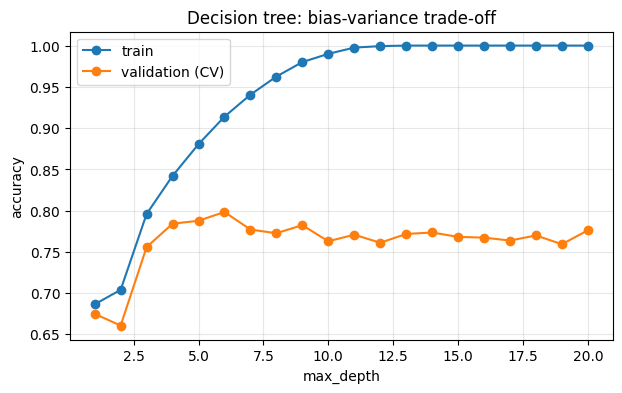

Best depth by CV: 6


In [7]:
depths = range(1, 21)
# Vamos a usar 5 folds en un cross validation para poder obtener los valores que van a ser ploteados.
train_s, val_s = validation_curve(DecisionTreeClassifier(), X_train, y_train,
                                  param_name="max_depth", param_range=depths, cv=5)
# Todo esto es para plotear las curvas 
plt.plot(depths, train_s.mean(1), "o-", label="train")
plt.plot(depths, val_s.mean(1), "o-", label="validation (CV)")
plt.xlabel("max_depth"); plt.ylabel("accuracy"); plt.title("Decision tree: bias-variance trade-off")
plt.legend(); plt.grid(alpha=.3); plt.show()
best_depth = list(depths)[val_s.mean(1).argmax()]
print("Best depth by CV:", best_depth)

Comparando todas las profundidades, vemos que más allá de un altura 6, el árbol no obtiene mejoras en el ajuste del conjunto de datos de validación, aunque sigue mejorando el de entrenamiento. Esto es sobreajuste. Así que el mejor árbol que podemos tener tiene altura 6 antes de que empiece a sobreajustar

In [10]:
tree_pruned = DecisionTreeClassifier(max_depth=best_depth)
tree_pruned.fit(X_train, y_train)
print(f"Pruned tree  -> train: {tree_pruned.score(X_train, y_train):.3f} | test: {tree_pruned.score(X_test, y_test):.3f}")

Pruned tree  -> train: 0.901 | test: 0.829


## 3. Bagging (Bootstrap Aggregating)
Vamos a probar con Bagging. Vamos a entrenar múltiples árboles, cada uno con un muestreo bootstrap (aleatorio con repetición). Luego, vamos a combinar las predicciones votando cual es la más predicha en cada caso. 
Si promediamos múltiples árboles que tienen una alta varianza y bajo bias, la varianza se debería reducir. 


In [12]:
bag = BaggingClassifier(estimator=DecisionTreeClassifier(), n_estimators=100,
                        oob_score=True, n_jobs=-1).fit(X_train, y_train)
print(f"Test accuracy: {bag.score(X_test, y_test):.3f}")
print(f"Out-of-bag (OOB) score: {bag.oob_score_:.3f}   <- estimación del accuracy sin usar CV")

Test accuracy: 0.891
Out-of-bag (OOB) score: 0.878   <- estimación del accuracy sin usar CV


## 4. Random Forest

Usaremos random forest ahora con 300 estimadores (300 sub árboles.)
También aquí podemos evaluar la importancia de cada atributo.

Random Forest test accuracy: 0.907 | OOB: 0.881


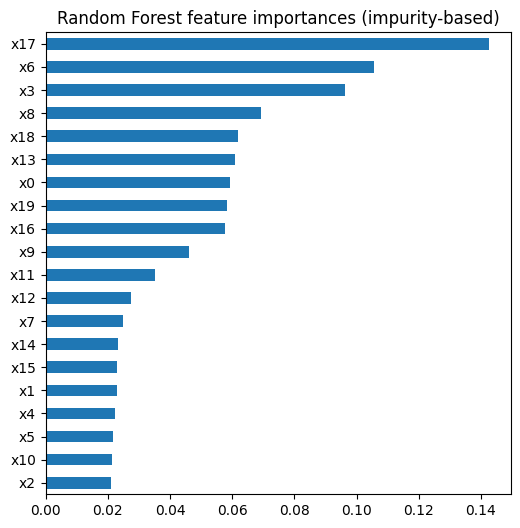

In [13]:
rf = RandomForestClassifier(n_estimators=300, oob_score=True, n_jobs=-1).fit(X_train, y_train)
print(f"Random Forest test accuracy: {rf.score(X_test, y_test):.3f} | OOB: {rf.oob_score_:.3f}")

imp = pd.Series(rf.feature_importances_, index=[f"x{i}" for i in range(X.shape[1])]).sort_values()
imp.plot.barh(figsize=(6, 6), title="Random Forest feature importances (impurity-based)"); plt.show()

## 6. Boosting

Los modelos de boosting son entrenados de manera secuencial, intentando predecir aquellos elementos que los modelos anteriores no predijeron. Para esto se usan árboles muy "bajos" para reducir el bías.

### 6.1 AdaBoost

El ejemplo clásico es AdaBoost, que asigna pesos a los casos que se clasificaron mal para que en la próxima iteración tengan más preponderancia en el proceso y el learner los tenga más en cuenta.

In [15]:
ada = AdaBoostClassifier(estimator=DecisionTreeClassifier(max_depth=1), n_estimators=200,
                         learning_rate=0.5).fit(X_train, y_train)
print(f"AdaBoost test accuracy: {ada.score(X_test, y_test):.3f}")

AdaBoost test accuracy: 0.845


### 6.2 Gradient Boosting

Cada árbol intenta predecir los errores del árbol anterior. 

Gradient Boosting test accuracy: 0.880


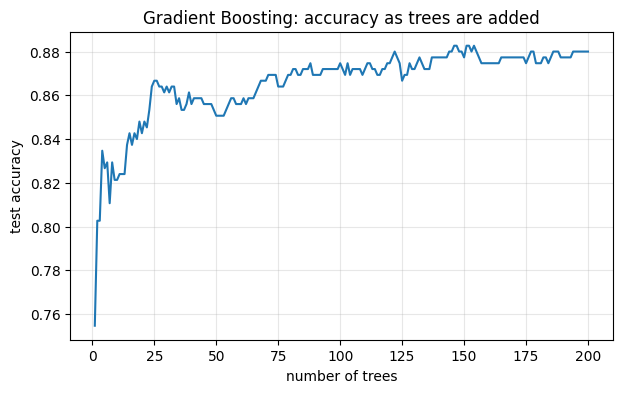

In [17]:
gb = GradientBoostingClassifier(n_estimators=200, learning_rate=0.1, max_depth=3).fit(X_train, y_train)
print(f"Gradient Boosting test accuracy: {gb.score(X_test, y_test):.3f}")

# Staged predictions: test accuracy as trees are added
staged = [accuracy_score(y_test, p) for p in gb.staged_predict(X_test)]
plt.plot(range(1, len(staged)+1), staged)
plt.xlabel("number of trees"); plt.ylabel("test accuracy"); plt.title("Gradient Boosting: accuracy as trees are added")
plt.grid(alpha=.3); plt.show()

## 7. Heterogeneous ensembles: Voting y Stacking

Estos métodos combinan diferentes algoritmos en vez de usar siempre el mismo.

- **Voting:** agrega las predicciones
- **Stacking:** se entrena otro modelo para que haga la predicción final

In [19]:
base_models = [
    ("lr",  make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))),
    ("knn", make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=15))),
    ("rf",  RandomForestClassifier(n_estimators=200, n_jobs=-1)),
    ("gb",  GradientBoostingClassifier()),
]
vote = VotingClassifier(estimators=base_models, voting="soft").fit(X_train, y_train)
stack = StackingClassifier(estimators=base_models, final_estimator=LogisticRegression(max_iter=1000),
                           cv=5, n_jobs=-1).fit(X_train, y_train)
print(f"Voting (soft) test accuracy: {vote.score(X_test, y_test):.3f}")
print(f"Stacking      test accuracy: {stack.score(X_test, y_test):.3f}")

Voting (soft) test accuracy: 0.891
Stacking      test accuracy: 0.901


## 8. Vamos a comparar todo ahora con cross-validation
esto puede tardar...

In [20]:
models = {
    "Decision Tree (full)":   DecisionTreeClassifier(),
    "Decision Tree (pruned)": DecisionTreeClassifier(max_depth=best_depth),
    "Bagging":                BaggingClassifier(estimator=DecisionTreeClassifier(), n_estimators=100),
    "Random Forest":          RandomForestClassifier(n_estimators=300),
    "Extra Trees":            ExtraTreesClassifier(n_estimators=300),
    "AdaBoost":               AdaBoostClassifier(estimator=DecisionTreeClassifier(max_depth=1), n_estimators=200, learning_rate=0.5),
    "Gradient Boosting":      GradientBoostingClassifier(),
    "Voting (soft)":          VotingClassifier(estimators=base_models, voting="soft"),
    "Stacking":               StackingClassifier(estimators=base_models, final_estimator=LogisticRegression(max_iter=1000), cv=5),
}

cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=3)
scores, rows = {}, []
for name, m in models.items():
    t0 = time.time()
    s = cross_val_score(m, X, y, cv=cv, scoring="accuracy", n_jobs=-1)
    scores[name] = s
    rows.append({"model": name, "mean_acc": s.mean(), "std": s.std(), "cv_time_s": time.time() - t0})

results = pd.DataFrame(rows).sort_values("mean_acc", ascending=False).reset_index(drop=True)
results.round(4)

,model,mean_acc,std,cv_time_s
0,Extra Trees,0.8913,0.0210,1.5813
1,Bagging,0.8838,0.0183,3.0222
2,Stacking,0.8820,0.0205,17.6754
3,Voting (soft),0.8796,0.0171,3.5648
4,Random Forest,0.8771,0.0156,2.7695
5,Gradient Boosting,0.8744,0.0193,1.4723
6,Decision Tree (pruned),0.8213,0.0262,0.1592
7,AdaBoost,0.8176,0.0172,1.8667
8,Decision Tree (full),0.7927,0.0234,3.2836


C:\Users\gdrot\AppData\Local\Temp\ipykernel_17352\906425205.py:3: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot([scores[n] for n in order][::-1], vert=False, labels=order[::-1])


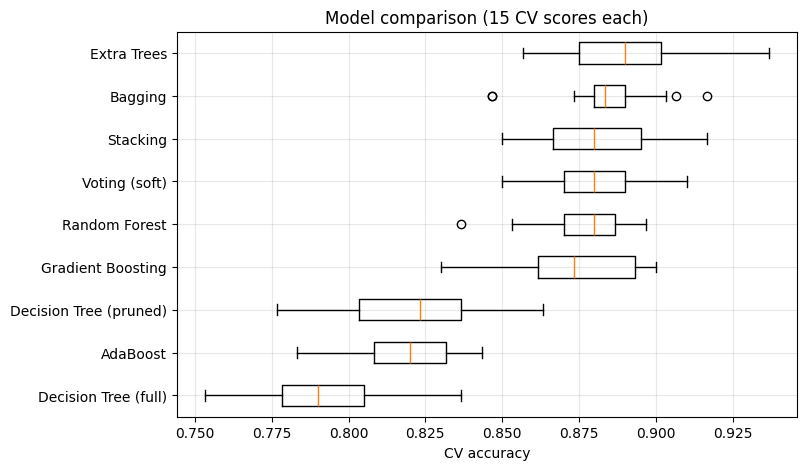

In [21]:
order = results["model"].tolist()
plt.figure(figsize=(8, 5))
plt.boxplot([scores[n] for n in order][::-1], vert=False, labels=order[::-1])
plt.xlabel("CV accuracy"); plt.title("Model comparison (15 CV scores each)"); plt.grid(alpha=.3); plt.show()

## 9. Confusion matrices: árbol de decisión vs. mejor modelo de ensemble

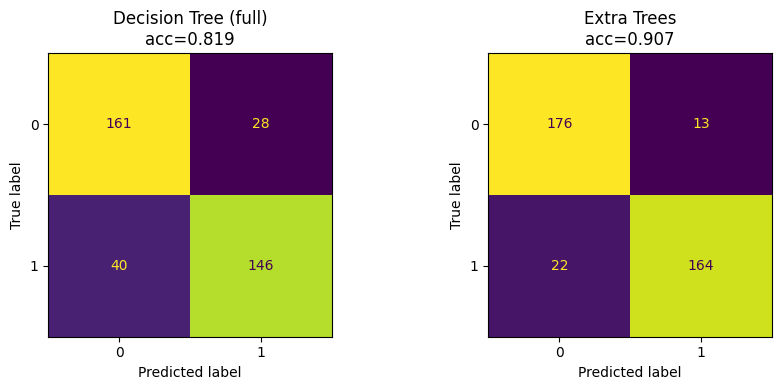

In [23]:
best_name = results.loc[0, "model"]
best_model = models[best_name].fit(X_train, y_train)
fig, axes = plt.subplots(1, 2, figsize=(9, 4))
for ax, (title, m) in zip(axes, [("Decision Tree (full)", tree), (best_name, best_model)]):
    ConfusionMatrixDisplay.from_estimator(m, X_test, y_test, ax=ax, colorbar=False)
    ax.set_title(f"{title}\nacc={m.score(X_test, y_test):.3f}")
plt.tight_layout(); plt.show()

## 11. Regresión lineal
Se puede aplicar lo mismo con regresión

In [32]:
Xd, yd = load_diabetes(return_X_y=True)
Xd_tr, Xd_te, yd_tr, yd_te = train_test_split(Xd, yd, test_size=0.25)

reg_models = {
    "Decision Tree":     DecisionTreeRegressor(),
    "Random Forest":     RandomForestRegressor(n_estimators=300, n_jobs=-1),
    "Gradient Boosting": GradientBoostingRegressor(n_estimators=200, learning_rate=0.05, max_depth=3),
}
out = []
for name, m in reg_models.items():
    r2 = cross_val_score(m, Xd, yd, cv=5, scoring="r2").mean()
    out.append({"model": name, "CV R²": r2})
pd.DataFrame(out).round(3)

,model,CV R²
0,Decision Tree,-0.162
1,Random Forest,0.423
2,Gradient Boosting,0.394
